# Central fotovoltaica · Análisis en Python (corte 3)

Procesa las medidas del ESP32 (sensores INA260) y genera gráficas y tablas.
Ejecutar de arriba abajo: **Kernel → Restart & Run All**. Requiere `pandas`, `numpy`, `matplotlib` y `openpyxl`.

| Nodo | Qué mide |
|---|---|
| entrada (`0x40`) | paneles o batería, según la prueba |
| salida (`0x44`) | salida del elevador MT3608 (5 V) hacia los LEDs |

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
from fisica import *

SAL = RAIZ / "graficas"; TAB = RAIZ / "tablas"
SAL.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
AZUL, NAR, VERDE, ROJO, GRIS, AMAR = "#004883", "#eb6834", "#1f9d55", "#c0392b", "#5b6672", "#e0a800"
plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.8})
pd.set_option("display.precision", 3)
RES = {}  # números que usa la presentación
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(SAL / nombre, bbox_inches="tight"); plt.show()

## Requerimiento 1 · Procesamiento de datos y modelado físico

### 1.1 Funciones físicas
Definidas en `fisica.py`. Unidades: V, mA, mW, mWh, s, Ω.

| Función | Ecuación |
|---|---|
| `ohm_v`, `ohm_i`, `ohm_r` | V = I · R |
| `potencia` | P = V · I |
| `energia` | E = ∫ P dt (regla del trapecio) |
| `eficiencia` | η = P<sub>sal</sub> / P<sub>ent</sub> · 100 |
| `error_pct` | \|real − teórico\| / \|teórico\| · 100 |

In [2]:
# Prueba rápida de las funciones con valores conocidos.
print("V con 22.5 mA y 222 Ω :", ohm_v(22.5, 222), "V")
print("R con 5 V y 22.5 mA   :", ohm_r(5.0, 22.5), "Ω")
print("P con 5 V y 22.5 mA   :", potencia(5.0, 22.5), "mW")
print("E de 100 mW por 1 h   :", round(energia(np.arange(0, 3601, 5), np.full(721, 100))[-1], 3), "mWh")
print("η 131 de 157 mW       :", round(eficiencia(131, 157), 1), "%")

V con 22.5 mA y 222 Ω : 4.995 V
R con 5 V y 22.5 mA   : 222.22222222222223 Ω
P con 5 V y 22.5 mA   : 112.5 mW
E de 100 mW por 1 h   : 100.0 mWh
η 131 de 157 mW       : 83.4 %


### 1.2 Importar los datos
Cada Excel que descarga la página del ESP32 trae la hoja `Prueba N`. Se cargan todas en un solo `DataFrame`.
Se usan las 10 pruebas del segundo lote más P8 (descarga completa) y P9 (carga) del primero.

In [3]:
d = cargar()
print(d.shape[0], "filas ·", d.prueba.nunique(), "pruebas")
pruebas = d.groupby("prueba").agg(fuente=("fuente", "first"), nombre=("nombre", "first"), filas=("n", "size"),
                                  inicio=("fecha", "min"), horas=("h", "max"))
display(pruebas)
d.head()

20954 filas · 12 pruebas


,fuente,nombre,filas,inicio,horas
prueba,,,,,
1,bateria,Paneles · Consumo energético 3#,2046,2026-11-02 17:49:05.278,2.842
3,paneles,Paneles · Generación energética #3,1444,2026-11-03 15:04:57.137,2.005
4,bateria,Batería · Consumo energético #4,2075,2026-11-03 18:03:18.057,2.881
5,bateria,Batería · Consumo energético #5,508,2026-11-04 10:19:12.102,0.702
6,paneles,Paneles · Generación energética #4,674,2026-11-04 11:03:22.186,0.935
8,bateria,,3295,2026-10-17 20:36:36.287,4.575
9,carga,,240,2026-10-18 07:42:53.023,0.332
19,paneles,Generación energética 2#,4019,2026-10-30 07:33:50.296,6.328
20,bateria,Consumo energético 1#,41,2026-10-30 16:28:32.448,4.840


,n,fecha,t,V,I,P_esp,E_esp,Vs,Is,Ps_esp,Es_esp,nombre,prueba,fuente,h
0,1,2026-11-02 17:49:05.278,0.278,1.859,0.0,0.00,0.000,1.684,0.0,0.000,0.000,Paneles · Consumo energético 3#,1,bateria,7.722e-05
1,2,2026-11-02 17:49:10.278,5.278,1.856,0.0,0.00,0.000,1.679,0.0,0.000,0.000,Paneles · Consumo energético 3#,1,bateria,1.466e-03
2,3,2026-11-02 17:49:15.279,10.279,3.893,40.0,155.72,0.216,4.991,26.3,131.263,0.182,Paneles · Consumo energético 3#,1,bateria,2.855e-03
3,4,2026-11-02 17:49:20.356,15.356,3.893,40.0,155.72,0.436,4.991,26.3,131.263,0.367,Paneles · Consumo energético 3#,1,bateria,4.266e-03
4,5,2026-11-02 17:49:25.358,20.358,3.891,40.0,155.64,0.652,4.993,26.3,131.316,0.550,Paneles · Consumo energético 3#,1,bateria,5.655e-03


### 1.3 Calcular potencia y energía con el script
El ESP32 ya entrega P y E. Aquí se recalculan desde V e I para comprobarlos.
El ESP32 suma la energía por rectángulos; aquí se usa la regla del trapecio.

In [4]:
d["P"] = potencia(d.V, d.I); d["Ps"] = potencia(d.Vs, d.Is)
d["E"] = d.groupby("prueba", group_keys=False).apply(lambda g: pd.Series(energia(g.t, g.P), g.index))
d["Es"] = d.groupby("prueba", group_keys=False).apply(lambda g: pd.Series(energia(g.t, g.Ps), g.index))
d["R_carga"] = ohm_r(d.Vs, d.Is)  # resistencia equivalente de los LEDs por Ohm
fin = d.groupby("prueba").agg(E_py=("E", "last"), E_esp=("E_esp", "max"), Es_py=("Es", "last"), Es_esp=("Es_esp", "max"))
fin["dif_E_%"] = error_pct(fin.E_esp, fin.E_py)
display(fin.round(2))
print("Diferencia máxima de potencia P = V·I contra el ESP32:", np.nanmax(np.abs(d.P - d.P_esp)).round(3), "mW")
RES["energia"] = {int(p): [round(r.E_py, 1), round(r.E_esp, 1), round(r["dif_E_%"], 2)] for p, r in fin.iterrows()}
RES["dif_P_max"] = round(float(np.nanmax(np.abs(d.P - d.P_esp))), 3)

,E_py,E_esp,Es_py,Es_esp,dif_E_%
prueba,,,,,
1,445.45,445.04,372.74,372.41,0.09
3,292.51,292.19,241.69,241.42,0.11
4,453.96,453.82,377.79,377.66,0.03
5,96.60,96.69,83.20,83.28,0.10
6,9.48,9.48,8.56,8.56,0.00
8,3722.51,3722.53,3138.88,3138.86,0.00
9,351.14,350.00,234.25,234.24,0.32
19,767.70,765.59,618.27,616.62,0.28
20,3.09,3.20,2.48,2.57,3.39


Diferencia máxima de potencia P = V·I contra el ESP32: 0.0 mW


### 1.4 Limpiar los datos
Problemas en las lecturas crudas:
- filas con el sistema apagado o con el sensor sin corriente (0 mA),
- picos sueltos a 0 V por falsos contactos (P9),
- ruido de ±1 paso del sensor (1.25 mV · 1.25 mA).

Filtro en dos pasos con NumPy: **mediana móvil** de 5 muestras (quita picos) y **media móvil** de 12 muestras = 60 s (suaviza).
El filtro trabaja por tramos: no promedia a través de huecos de más de 60 s.

In [5]:
dl = limpiar(d)
quitadas = (d.groupby("prueba").size() - dl.groupby("prueba").size()).fillna(0).astype(int)
print("Filas quitadas por prueba:"); display(quitadas.to_frame("filas").T)
RES["R_carga"] = {int(p): round(v) for p, v in dl.groupby("prueba").R_carga.median().items()}
# Filtro por prueba para no mezclar el final de una con el inicio de otra.
for c in ["V", "I", "Vs", "Is"]:
    dl[c + "_f"] = dl.groupby("prueba")[c].transform(lambda x: filtrar(x.values, dl.t[x.index].values))

Filas quitadas por prueba:


prueba,1,3,4,5,6,8,9,19,20,22,23,24
filas,2,0,2,2,48,0,47,6,24,2,0,5


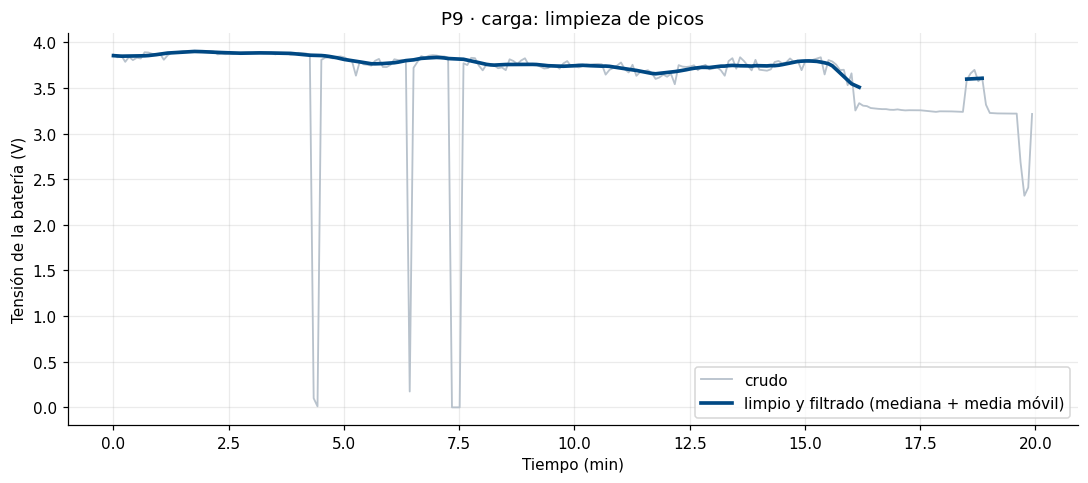

,σ crudo (mV),σ filtrado (mV)
1,0.941,0.069
3,6.410,3.508
4,0.718,0.056
5,0.724,0.055
6,43.781,5.032
8,0.996,0.070
19,34.924,9.599
22,1.220,0.103
23,1.137,0.059
24,0.829,0.061


In [6]:
# P9: lecturas crudas con picos a 0 V frente a la señal limpia y filtrada.
g, gl = d[d.prueba == 9], dl[dl.prueba == 9]
fig, ax = plt.subplots()
ax.plot(g.t / 60, g.V, color="#b8c2cc", lw=1.2, label="crudo")
tf, vf = con_huecos(gl.t, gl.V_f)
ax.plot(tf / 60, vf, color=AZUL, lw=2.4, label="limpio y filtrado (mediana + media móvil)")
ax.set(xlabel="Tiempo (min)", ylabel="Tensión de la batería (V)", title="P9 · carga: limpieza de picos")
ax.legend(); guardar(fig, "r1_limpieza.png")
# Variación entre lecturas seguidas de la salida, antes y después del filtro.
ruido = pd.DataFrame({p: {"σ crudo (mV)": 1000 * np.std(np.diff(g.Vs)), "σ filtrado (mV)": 1000 * np.std(np.diff(g.Vs_f))}
                      for p, g in dl.groupby("prueba") if len(g) > 200}).T
display(ruido.round(3))
RES["limpieza"] = {"filas": int(d.shape[0]), "quitadas": int(quitadas.sum()),
                   "ruido_crudo": round(ruido.iloc[:, 0].median(), 2), "ruido_filtrado": round(ruido.iloc[:, 1].median(), 2)}
RES["serie_crudo"] = g[["t", "V"]].assign(t=g.t / 60).round(3).values.tolist()
RES["serie_filtrado"] = gl[["t", "V_f"]].assign(t=gl.t / 60).round(3).values.tolist()

## Requerimiento 2 · Análisis de datos y eficiencia

### 2.1 Eficiencia del convertidor MT3608
η = P<sub>salida</sub> / P<sub>entrada</sub>. Solo tiene sentido cuando la entrada es la batería.

In [7]:
bat = dl[dl.fuente == "bateria"]
ef = bat.groupby("prueba").apply(lambda g: pd.Series({
    "P_ent (mW)": g.P.mean(), "P_sal (mW)": g.Ps.mean(), "pérdida (mW)": (g.P - g.Ps).mean(),
    "η (%)": eficiencia(g.Es.iloc[-1] - g.Es.iloc[0], g.E.iloc[-1] - g.E.iloc[0]) if g.E.iloc[-1] > 1 else np.nan,
    "R carga (Ω)": g.R_carga.median()}), include_groups=False)
ef = ef[bat.groupby("prueba").size() > 100]  # P20 solo tiene 17 muestras válidas
display(ef.round(1))
# P8: la eficiencia baja cuando cae la tensión de la batería.
g8 = dl[dl.prueba == 8].copy()
g8["eta"] = eficiencia(g8.Ps, g8.P)
tramos = g8.groupby(pd.cut(g8.V, [2.8, 3.0, 3.2, 3.4, 3.5, 3.6, 3.7]), observed=True).eta.mean()
display(tramos.round(1).to_frame("η (%)"))
RES["eficiencia"] = {int(k): round(v, 1) for k, v in ef["η (%)"].dropna().items()}
RES["perdida"] = {int(k): round(v, 1) for k, v in ef["pérdida (mW)"].items()}
RES["eta_vs_v"] = [[round(iv.mid, 2), round(v, 1)] for iv, v in tramos.items()]

,P_ent (mW),P_sal (mW),pérdida (mW),η (%),R carga (Ω)
prueba,,,,,
1,156.9,131.3,25.6,83.7,189.8
4,157.7,131.2,26.5,83.2,189.7
5,138.0,118.9,19.1,86.1,210.1
8,813.6,686.1,127.6,84.3,35.6
22,170.1,131.2,38.9,77.1,189.8
24,157.5,131.7,25.8,83.6,190.1


,η (%)
V,
"(2.8, 3.0]",80.9
"(3.0, 3.2]",82.4
"(3.2, 3.4]",83.7
"(3.4, 3.5]",84.4
"(3.5, 3.6]",85.0
"(3.6, 3.7]",85.4


### 2.2 Error porcentual: teórico contra real
| Comparación | Teórico | Real |
|---|---|---|
| Potencia | P = V · I (Python) | potencia que guardó el ESP32 |
| Energía | trapecios (Python) | rectángulos del ESP32 |
| Salida del MT3608 | consigna de 5.00 V | tensión medida en `0x44` (solo con batería: con panel se apaga al irse el sol) |
| Corriente de la batería (P8) | potencia constante: I = P<sub>sal</sub> / (η · V) | corriente medida |
| Eficiencia | 97 % (máximo de la hoja de datos) | η medida |

In [8]:
eta0 = g8.eta.median() / 100
g8["I_teo"] = g8.Ps / (eta0 * g8.V)  # el elevador pide más corriente cuando baja la tensión
filas = [
    ["Potencia P = V·I", "todas", np.nanmean(error_pct(dl.P, dl.P_esp))],
    ["Energía (trapecio vs ESP32)", "todas", fin["dif_E_%"].mean()],
    ["Salida 5.00 V", "batería 30 oct-4 nov", error_pct(5.0, bat[~bat.prueba.isin([8, 9])].Vs).mean()],
    ["Salida 5.00 V", "P8 y P9 (17-18 oct)", error_pct(5.0, dl[dl.prueba.isin([8, 9])].Vs).mean()],
    ["Corriente potencia constante", "P8", error_pct(g8.I_teo, g8.I).mean()],
    ["Eficiencia hoja de datos 97 %", "con batería", error_pct(97, ef["η (%)"].dropna()).mean()],
]
errores = pd.DataFrame(filas, columns=["Comparación", "Pruebas", "Error medio (%)"])
display(errores.round(3))
RES["errores"] = errores.round(3).values.tolist()
RES["eta0"] = round(eta0 * 100, 1)

,Comparación,Pruebas,Error medio (%)
0,Potencia P = V·I,todas,0.000
1,Energía (trapecio vs ESP32),todas,0.383
2,Salida 5.00 V,batería 30 oct-4 nov,0.144
3,Salida 5.00 V,P8 y P9 (17-18 oct),1.167
4,Corriente potencia constante,P8,0.922
5,Eficiencia hoja de datos 97 %,con batería,14.417


### 2.3 Modelo de descarga y autonomía
Regresión polinómica de grado 4 de la tensión de la batería contra el tiempo (P8, descarga completa hasta 2.81 V).
La autonomía de cada carga se estima con **t = E<sub>batería</sub> / P<sub>entrada</sub>**, usando la energía medida en P8.
Son valores mínimos: P8 empezó en 3.63 V, sin carga completa.

V(t) = -0.0130·t^4 +0.0964·t^3 -0.2295·t^2 +0.1165·t^1 +3.6046·t^0
R² = 0.9960 · raíz del error cuadrático medio (RMSE) = 10.4 mV


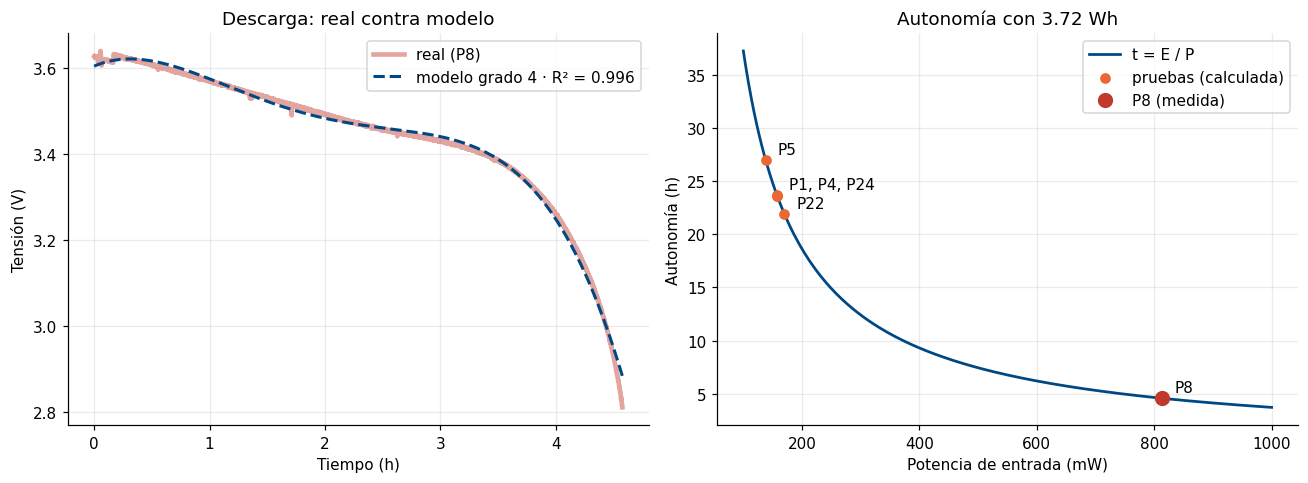

,P,t_h
prueba,,
1,156.9,23.7
4,157.7,23.6
5,138.0,27.0
8,813.6,4.6
22,170.1,21.9
24,157.5,23.6


Pendiente de la meseta con LEDs (mV/h): {1: -9.9, 4: -15.9, 5: -10.2, 22: -10.0, 24: -8.6}


In [9]:
coef = np.polyfit(g8.h, g8.V, 4)
g8["V_mod"] = np.polyval(coef, g8.h)
r2 = 1 - ((g8.V - g8.V_mod) ** 2).sum() / ((g8.V - g8.V.mean()) ** 2).sum()
rmse = np.sqrt(((g8.V - g8.V_mod) ** 2).mean())
print("V(t) =", " ".join(f"{c:+.4f}·t^{4 - k}" for k, c in enumerate(coef)))
print(f"R² = {r2:.4f} · raíz del error cuadrático medio (RMSE) = {1000 * rmse:.1f} mV")
E_bat = g8.E.iloc[-1] / 1000  # Wh entregados hasta el corte
P = np.linspace(100, 1000, 200)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(g8.h, g8.V, color=ROJO, lw=3, alpha=.45, label="real (P8)")
ax[0].plot(g8.h, g8.V_mod, "--", color=AZUL, lw=2, label=f"modelo grado 4 · R² = {r2:.3f}")
ax[0].set(xlabel="Tiempo (h)", ylabel="Tensión (V)", title="Descarga: real contra modelo"); ax[0].legend()
ax[1].plot(P, E_bat * 1000 / P, color=AZUL, label="t = E / P")
auto = ef["P_ent (mW)"].to_frame("P")
auto["t_h"] = E_bat * 1000 / auto.P
ax[1].scatter(auto.P, auto.t_h, color=NAR, zorder=3, label="pruebas (calculada)")
ax[1].scatter([g8.P.mean()], [g8.h.max()], color=ROJO, s=80, zorder=4, label="P8 (medida)")
# Una etiqueta por grupo de puntos casi iguales para que no se encimen.
for t_h, grupo in auto.groupby(auto.t_h.round(0)):
    ax[1].annotate(", ".join(f"P{p}" for p in grupo.index), (grupo.P.mean(), grupo.t_h.mean()), xytext=(8, 4), textcoords="offset points")
ax[1].set(xlabel="Potencia de entrada (mW)", ylabel="Autonomía (h)", title=f"Autonomía con {E_bat:.2f} Wh"); ax[1].legend()
guardar(fig, "r2_descarga_autonomia.png")
display(auto.round(1))
pend = dl[dl.prueba.isin([1, 4, 5, 22, 24])].groupby("prueba").apply(lambda g: 1000 * np.polyfit(g.h, g.V, 1)[0], include_groups=False)
print("Pendiente de la meseta con LEDs (mV/h):", pend.round(1).to_dict())
RES["modelo"] = {"coef": coef.round(5).tolist(), "r2": round(r2, 4), "rmse_mV": round(1000 * rmse, 1), "E_Wh": round(E_bat, 3),
                 "t_corte": round(g8.h.max(), 2), "P8_mW": round(g8.P.mean(), 1), "n": int(len(g8))}
RES["autonomia"] = {int(p): [round(r.P, 1), round(r.t_h, 1)] for p, r in auto.iterrows()}
RES["pendiente"] = {int(k): round(v, 1) for k, v in pend.items()}
paso = max(1, len(g8) // 140)
cols = ["h", "V", "V_mod", "I", "I_teo"]
RES["serie_descarga"] = pd.concat([g8[cols].iloc[::paso], g8[cols].iloc[[-1]]]).drop_duplicates().round(3).values.tolist()  # incluye el corte final
RES["V_corte"] = round(g8.V.iloc[-1], 2)

### 2.4 Detectar pérdidas y caídas de tensión
- **Saltos bruscos**: `np.diff` sobre la tensión; se marca todo salto mayor que 8 veces la variación típica, con un mínimo de 50 mV.
- **Resistencia en serie**: en P9 la tensión sube y baja con la corriente de carga.
  Regresión V = V<sub>0</sub> + R · I: la pendiente suma la resistencia interna de las celdas, cables, contactos y portapilas.
- **Pérdida en el elevador**: P<sub>ent</sub> − P<sub>sal</sub>.

prueba,1,3,4,5,6,8,9,19,20,22,23,24
saltos > umbral,1,5,0,11,56,0,7,135,0,4,14,0
picos a 0 V,0,0,0,0,0,0,1,0,0,0,0,0


P9: V = 3.153 V + 1.80 Ω · I   (R² = 0.893, 192 puntos)
Con 0.4 A se pierden 0.72 V y 288 mW en esa resistencia (P = R·I²)


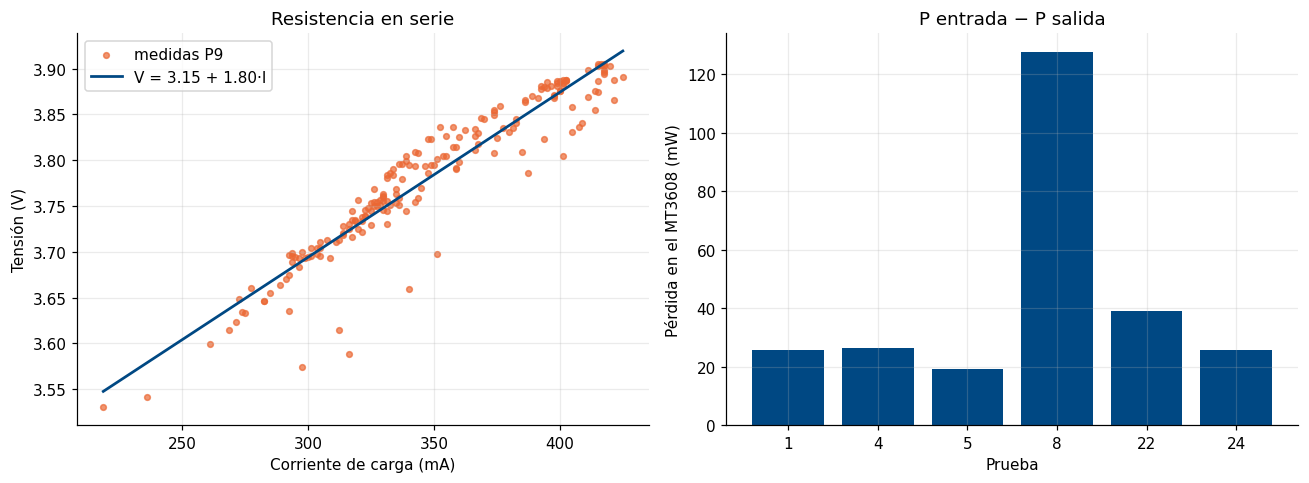

In [10]:
eventos = []
for p, g in d.groupby("prueba"):
    c = caidas(g.t.values, g.V.values, g.I.values)
    c = c[(c.V_antes > 1) & (c.V_despues > 1)]  # fuera encendidos, apagados y picos a 0 V
    eventos.append(c.assign(prueba=p))
ev = pd.concat(eventos)
picos0 = d.groupby("prueba").apply(lambda g: int(((g.V < 0.5) & (g.V.shift() > 3) & (g.V.shift(-1) > 3)).sum()), include_groups=False)
resumen_ev = pd.DataFrame({"saltos > umbral": ev.groupby("prueba").size(), "picos a 0 V": picos0}).fillna(0).astype(int)
display(resumen_ev.T)
g9 = d[(d.prueba == 9) & (d.V > 3) & (d.I > 50)]
R_serie, V0 = np.polyfit(g9.I / 1000, g9.V, 1)
r9 = np.corrcoef(g9.I, g9.V)[0, 1] ** 2
print(f"P9: V = {V0:.3f} V + {R_serie:.2f} Ω · I   (R² = {r9:.3f}, {len(g9)} puntos)")
print(f"Con 0.4 A se pierden {R_serie * 0.4:.2f} V y {R_serie * 0.4 ** 2 * 1000:.0f} mW en esa resistencia (P = R·I²)")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(g9.I, g9.V, s=14, color=NAR, alpha=.7, label="medidas P9")
x = np.linspace(g9.I.min(), g9.I.max(), 10)
ax[0].plot(x, V0 + R_serie * x / 1000, color=AZUL, label=f"V = {V0:.2f} + {R_serie:.2f}·I")
ax[0].set(xlabel="Corriente de carga (mA)", ylabel="Tensión (V)", title="Resistencia en serie"); ax[0].legend()
ax[1].bar(ef.index.astype(str), ef["pérdida (mW)"], color=AZUL)
ax[1].set(xlabel="Prueba", ylabel="Pérdida en el MT3608 (mW)", title="P entrada − P salida")
guardar(fig, "r2_perdidas.png")
RES["perdidas"] = {"R_serie": round(R_serie, 2), "V0": round(V0, 3), "r2": round(r9, 3), "n": int(len(g9)),
                   "picos0": int(picos0.sum()), "saltos": int(len(ev)), "puntos": g9[["I", "V"]].round(3).values.tolist()}

## Requerimiento 3 · Visualización y validación de resultados

### 3.1 Curvas superpuestas: teórico contra real

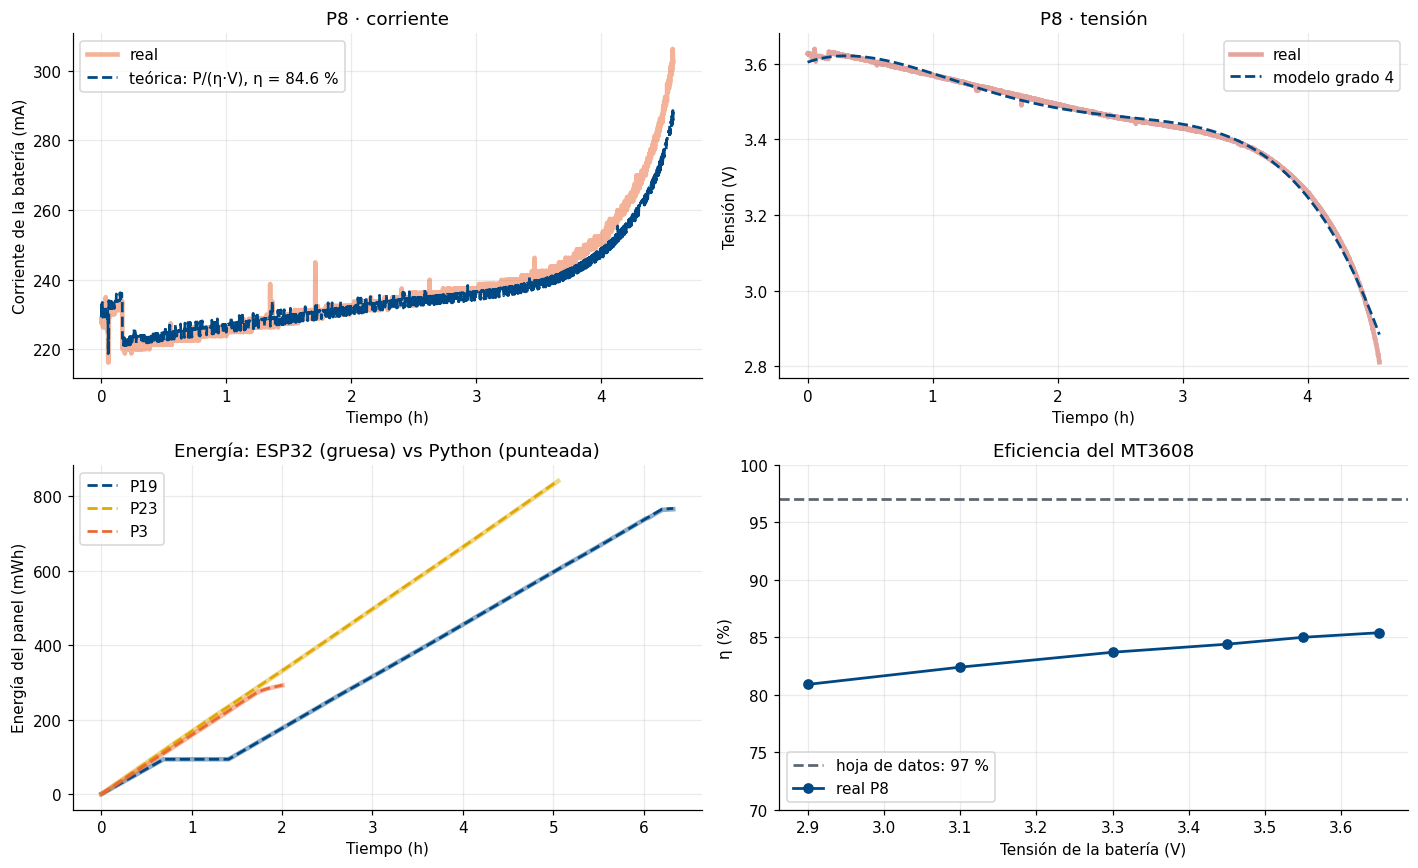

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
ax[0, 0].plot(g8.h, g8.I, color=NAR, lw=3, alpha=.5, label="real")
ax[0, 0].plot(g8.h, g8.I_teo, "--", color=AZUL, label=f"teórica: P/(η·V), η = {eta0 * 100:.1f} %")
ax[0, 0].set(xlabel="Tiempo (h)", ylabel="Corriente de la batería (mA)", title="P8 · corriente"); ax[0, 0].legend()
ax[0, 1].plot(g8.h, g8.V, color=ROJO, lw=3, alpha=.45, label="real")
ax[0, 1].plot(g8.h, g8.V_mod, "--", color=AZUL, label="modelo grado 4")
ax[0, 1].set(xlabel="Tiempo (h)", ylabel="Tensión (V)", title="P8 · tensión"); ax[0, 1].legend()
for p, c in [(19, AZUL), (23, AMAR), (3, NAR)]:
    g = d[d.prueba == p]
    ax[1, 0].plot(g.h - g.h.iloc[0], g.E_esp, color=c, lw=3, alpha=.45)
    ax[1, 0].plot(g.h - g.h.iloc[0], g.E, "--", color=c, label=f"P{p}")
ax[1, 0].set(xlabel="Tiempo (h)", ylabel="Energía del panel (mWh)", title="Energía: ESP32 (gruesa) vs Python (punteada)"); ax[1, 0].legend()
v, e = zip(*RES["eta_vs_v"])
ax[1, 1].axhline(97, color=GRIS, ls="--", label="hoja de datos: 97 %")
ax[1, 1].plot(v, e, "o-", color=AZUL, label="real P8")
ax[1, 1].set(xlabel="Tensión de la batería (V)", ylabel="η (%)", ylim=(70, 100), title="Eficiencia del MT3608"); ax[1, 1].legend()
guardar(fig, "r3_teorico_vs_real.png")

### 3.2 Tablas resumen para el informe

In [12]:
resumen = dl.groupby("prueba").agg(fuente=("fuente", "first"), horas=("h", "max"), muestras=("n", "size"),
    V_media=("V", "mean"), V_min=("V", "min"), V_max=("V", "max"), I_media=("I", "mean"),
    P_media=("P", "mean"), E_mWh=("E", "last"), Vs_media=("Vs", "mean"), Is_media=("Is", "mean"), Ps_media=("Ps", "mean"))
por_fuente = dl.groupby("fuente")[["V", "I", "P", "Vs", "Is", "Ps"]].describe().T
display(resumen.round(3)); display(por_fuente.round(3))
resumen.round(4).to_csv(TAB / "resumen_pruebas.csv", encoding="utf-8-sig")
with pd.ExcelWriter(TAB / "tablas_corte3.xlsx") as x:
    for nombre, t in {"Resumen": resumen, "Por fuente": por_fuente, "Eficiencia": ef, "Errores": errores.set_index("Comparación"),
                      "Autonomía": auto, "Eventos": resumen_ev}.items():
        t.round(4).to_excel(x, sheet_name=nombre)
print("Tablas guardadas en tablas/")
RES["resumen"] = resumen.reset_index()[["prueba", "fuente", "horas", "V_media", "P_media", "E_mWh"]].round(3).values.tolist()

,fuente,horas,muestras,V_media,V_min,V_max,I_media,P_media,E_mWh,Vs_media,Is_media,Ps_media
prueba,,,,,,,,,,,,
1,bateria,2.842,2044,3.867,3.851,3.893,40.567,156.865,445.451,4.991,26.301,131.262
3,paneles,2.005,1444,4.229,2.808,4.930,34.069,145.883,292.511,4.804,24.689,120.538
4,bateria,2.881,2073,3.870,3.849,3.899,40.744,157.680,453.964,4.989,26.302,131.220
5,bateria,0.702,506,3.846,3.675,3.875,35.891,138.031,96.597,5.000,23.781,118.897
6,paneles,0.928,626,2.227,2.007,2.345,4.819,10.783,9.479,2.648,3.692,9.820
8,bateria,4.575,3295,3.441,2.810,3.640,237.154,813.634,3722.512,4.942,138.831,686.066
9,carga,0.314,193,3.779,3.333,3.905,346.462,1313.273,350.354,4.940,143.067,706.785
19,paneles,6.328,4013,4.883,2.488,5.534,27.989,137.192,767.697,4.963,22.108,110.500
20,bateria,4.840,17,3.816,3.775,3.945,36.629,139.711,3.092,4.997,22.429,112.076


fuente      bateria     carga   paneles
V  count  10909.000   193.000  9714.000
   mean       3.718     3.779     4.704
   std        0.213     0.089     0.811
   min        2.810     3.333     2.007
   25%        3.585     3.725     4.558
   50%        3.854     3.786     4.930
   75%        3.875     3.849     5.224
   max        3.945     3.905     5.666
I  count  10909.000   193.000  9714.000
   mean     100.484   346.462    29.134
   std       90.323    49.884     7.624
   min       32.500     2.500     2.500
   25%       40.000   317.500    28.800
   50%       41.300   340.000    30.000
   75%      225.000   387.500    32.500
   max      306.300   425.000    46.300
P  count  10909.000   193.000  9714.000
   mean     356.360  1313.273   141.351
   std      300.959   212.322    40.370
   min      125.320     8.332     5.018
   25%      155.720  1188.720   138.943
   50%      159.831  1289.134   146.419
   75%      804.723  1493.436   165.507
   max      862.541  1653.675   173.740
Vs count  10909.000   193.000  9714.000
   mean       4.977     4.940     4.805
   std        0.024     0.003     0.630
   min        4.933     4.931     2.330
   25%        4.944     4.939     5.001
   50%        4.990     4.941     5.004
   75%        4.993     4.943     5.005
   max        5.003     4.945     5.046
Is count  10909.000   193.000  9714.000
   mean      60.170   143.067    22.929
   std       51.756     2.729     5.875
   min       21.300   140.000     2.500
   25%       26.300   141.300    22.500
   50%       26.300   141.300    23.800
   75%      138.800   146.300    26.300
   max      146.300   152.500    27.500
Ps count  10909.000   193.000  9714.000
   mean     298.278   706.785   113.681
   std      255.149    13.204    32.073
   min      106.394   691.740     5.825
   25%      131.237   698.163   112.612
   50%      131.316   698.446   112.792
   75%      685.533   721.990   131.605
   max      721.990   751.978   138.765

Tablas guardadas en tablas/


### 3.3 Estabilidad de la tensión
Desviación estándar (σ) con `np.std` y coeficiente de variación CV = σ / media.
La salida del MT3608 debe ser estable; la batería baja poco a poco y el panel cambia con el sol.

,fuente,Vs media (V),σ Vs (mV),CV Vs (%),σ V entrada (mV)
prueba,,,,,
1,bateria,4.991,0.890,0.018,8.275
3,paneles,4.804,478.936,9.970,573.099
4,bateria,4.989,0.817,0.016,13.211
5,bateria,5.000,0.641,0.013,22.338
6,paneles,2.648,100.678,3.802,60.979
8,bateria,4.942,2.225,0.045,163.532
9,carga,4.940,2.720,0.055,88.324
19,paneles,4.963,302.639,6.098,434.890
20,bateria,4.997,0.984,0.020,71.597


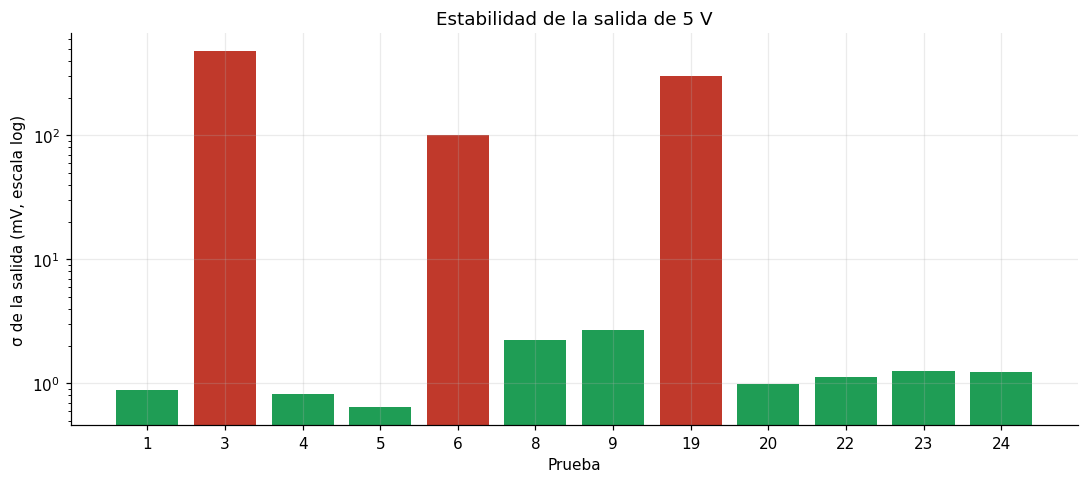

In [13]:
est = dl.groupby("prueba").apply(lambda g: pd.Series({
    "fuente": g.fuente.iat[0], "Vs media (V)": np.mean(g.Vs), "σ Vs (mV)": 1000 * np.std(g.Vs),
    "CV Vs (%)": 100 * np.std(g.Vs) / np.mean(g.Vs), "σ V entrada (mV)": 1000 * np.std(g.V)}), include_groups=False)
display(est.round(3))
estables = est[est["σ Vs (mV)"] < 10]
fig, ax = plt.subplots()
col = [VERDE if s < 10 else ROJO for s in est["σ Vs (mV)"]]
ax.bar(est.index.astype(str), est["σ Vs (mV)"], color=col)
ax.set(yscale="log", xlabel="Prueba", ylabel="σ de la salida (mV, escala log)", title="Estabilidad de la salida de 5 V")
guardar(fig, "r3_estabilidad.png")
RES["estabilidad"] = {int(p): [r.fuente, round(r["Vs media (V)"], 3), round(r["σ Vs (mV)"], 2)] for p, r in est.iterrows()}
RES["sigma_rango"] = [round(estables["σ Vs (mV)"].min(), 2), round(estables["σ Vs (mV)"].max(), 2)]

### 3.4 Datos para la presentación
Se guardan los números que usan las diapositivas, para que salgan del mismo cálculo.

In [14]:
(RAIZ / "resultados.json").write_text(json.dumps(RES, ensure_ascii=False, default=float), encoding="utf-8")
print("resultados.json listo ·", len(RES), "bloques")

resultados.json listo · 20 bloques
